# **WSINDy for PDEs (and ODEs): Examples**

- Based on the [JCP paper by **D. A. Messenger**, **D. M. Bortz** (2021)](https://www.sciencedirect.com/science/article/pii/S0021999121004204).
- See the authors' original [MatLab code repository](https://github.com/MathBioCU/WSINDy_PDE).

Seth Minor, 2026

---

This notebook demonstrates [PyWSINDy](https://github.com/SethMinor/PyWSINDy-for-PDEs) being applied to various spatiotemporal (PDE) and purely temporal (ODE) systems.

**PDE examples:**
- the Kuramoto Sivashinsky equation
    - $1$ state variable $(u)$
    - $0$ auxilliary variables
    - $1$ space dimension $(x)$
    - $1$ time dimension $(t)$
- the Swift Hohenberg equation
    - $1$ state variable $(u)$
    - $0$ auxilliary variables
    - $2$ space dimensions $(x,y)$
    - $1$ time dimension $(t)$
- the magnetic component of the ideal MHD equations
    - $3$ state variables $(b_1,b_2,b_3)$
    - $3$ aux. variables $(u_1,u_2,u_3)$
    - $3$ space dimensions $(x,y,z)$
    - $1$ time dimension $(t)$

**ODE examples:**
- the Logistic equation
    - $1$ state variables $(u)$
    - $0$ auxilliary variables
    - $0$ space dimensions
    - $1$ time dimension $(t)$
- the Lotka-Volterra equations
    - $2$ state variables $(x,y)$
    - $0$ auxilliary variables
    - $0$ space dimensions
    - $1$ time dimension $(t)$
- the Lorenz '63 equation
    - $3$ state variables $(x,y,z)$
    - $0$ auxilliary variables
    - $0$ space dimensions
    - $1$ time dimension $(t)$

This notebook also illustrates how to run automated hyperparameter sweeps.

In [1]:
import sys
sys.path.append('..')

import torch
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display,Math
from wsindy_dev import *

torch.set_default_dtype(torch.float64)

In [2]:
# Plot settings
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 12
plt.rcParams['figure.dpi'] = 100
#plt.rcParams['figure.dpi'] = 300

matplotlib.rc('xtick', labelsize=10, direction='out')
matplotlib.rc('ytick', labelsize=10, direction='out')

## **PDE EXAMPLES**

### **KURAMOTO SIVASHINSKY**

In this example, we use data from a numerical solution of the $(1+1)$-dimensional Kuramoto Sivashinsky equation: $$\begin{align*}
u_t = -\frac{1}{2}\left(u^2\right)_{x} - u_{xx} - u_{xxxx},
\quad \text{for} \quad
\begin{cases}
x \in [0, \, 32\pi],
\\
\, t \in [0, \, 150],
\end{cases}
\end{align*}$$ using periodic boundary conditions. See the [KS.txt](KS.txt) file (1.3 MB) located in the [Datasets](../Datasets) folder.

In [3]:
# Add observation noise?
noise = 0.2

Imported tensor with shape: (256, 301)


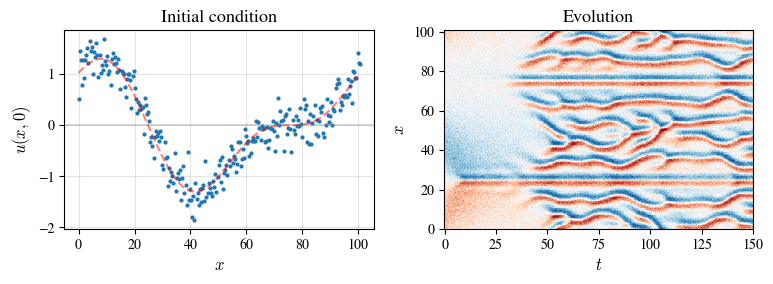

In [4]:
# IMPORT THE DATA
data_path = '../Datasets/KS.txt'
torch.manual_seed(0);

# Read in CSV data
U0 = torch.tensor(np.loadtxt(data_path, delimiter=','))
U = U0 if noise == 0 else add_noise(U0, noise)

# Reshape to Nx x ... x Nt tensor
[L, T] = [32*np.pi, 150]
[Nx, Nt] = [256, 301]
U = U.view(Nx, -1)
print(f"Imported tensor with shape: {U.numpy().shape}")

# Space and time
x = torch.linspace(0, L, Nx)
t = torch.linspace(0, T, Nt)

# Preview the data
X,T = torch.meshgrid(x, t, indexing='ij')
fig,ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(x, U[:,0], '.', ms=4)
ax[0].plot(x, U0[:,0], '--', color='r', alpha=0.5)
ax[0].axhline(0, color='gray', alpha=0.3)
ax[0].set_title('Initial condition', fontsize=13)
ax[0].set_xlabel('$x$')
ax[0].set_ylabel('$u(x,0)$')
ax[0].grid(True, color="gray", alpha=0.2)
pcm = ax[1].pcolormesh(T, X, U, cmap='RdBu_r')
ax[1].set_title('Evolution', fontsize=13)
ax[1].set_xlabel('$t$')
ax[1].set_ylabel('$x$')
fig.tight_layout()
plt.show()

del fig,ax,X,L,T

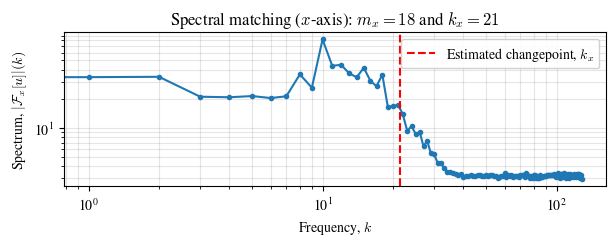

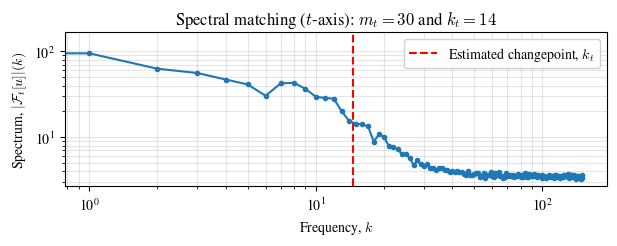

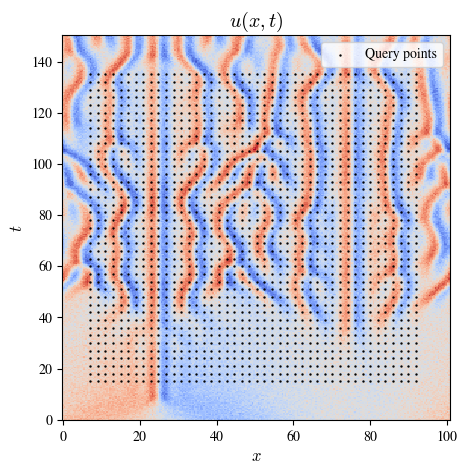

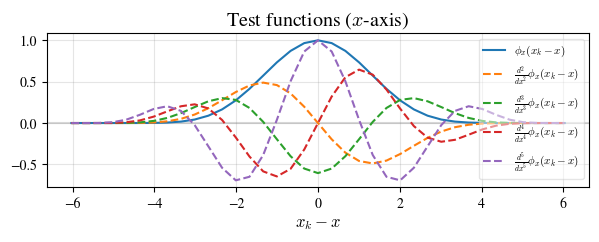

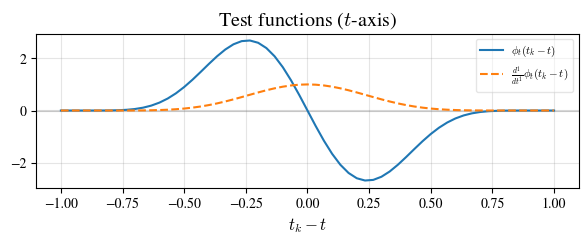

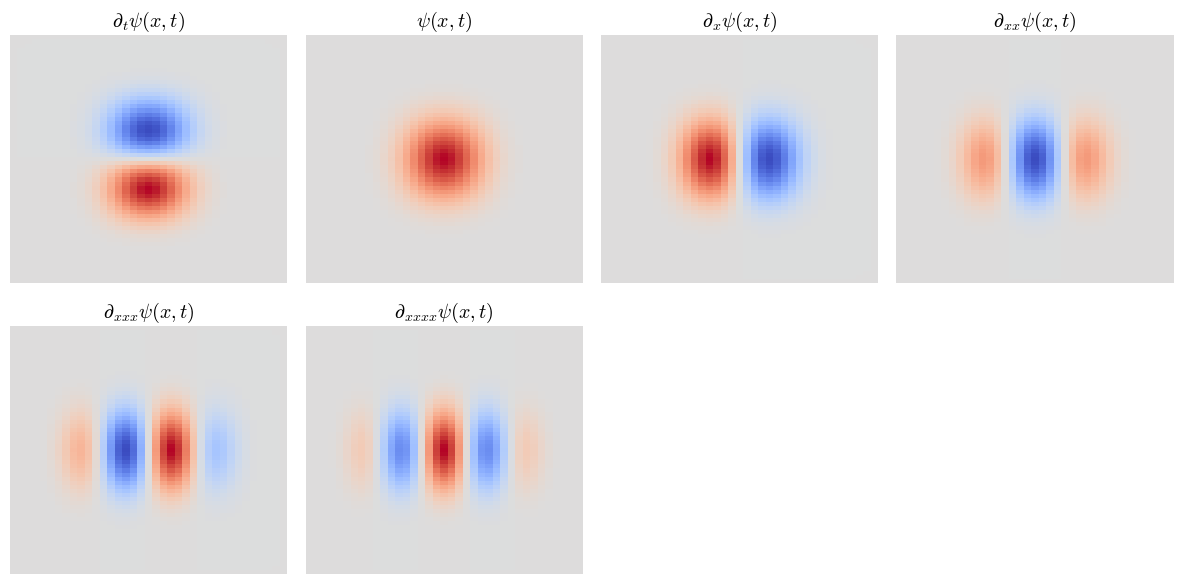

In [5]:
# Space-time grid
grid = [x,t]

# Derivative operators to include in library
derivatives = [[0,1], # d/dt
               [0,0], # identity
               [1,0], # d/dx
               [2,0], # d^2/dx^2
               [3,0], # d^3/dx^3
               [4,0]] # d^4/dx^4

# Candidate monomial terms to include in library
monomials = [[0], # constant
        [1], # u^1
        [2]] # u^2

model = WSINDy(U, derivatives, monomials, grid, equation_type='pde')

In [6]:
# Create standard library terms
[G,powers,derivs,rhs_names] = model.create_default_library()

# Display the library rendered in LaTex
lib_string = fr'\Theta({model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

100%|██████████| 5/5 [00:00<00:00, 111.52it/s]


<IPython.core.display.Math object>

In [7]:
# Example of adding a funky non-homogeneous term: D_i cos(u)
i = 1
kernel = model.test_fcn_kernels[i]
scales_product = np.prod(model.x_scales + [model.t_scale])
cos_term = compute_weak_trig(U, kernel, model.spacing, freq=1., phase=0., scales_product=scales_product)

G.append(cos_term[model.conv_mask])
powers.append([0])
derivs.append(i)
rhs_names.append(r'\cos(u)' + model.derivative_names[i])

# Display the library rendered in LaTex
lib_string = fr'\Theta({model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

del i, scales_product, kernel, cos_term

<IPython.core.display.Math object>

In [8]:
# Define WSINDy linear system
model.build_lhs()
model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
w = model.MSTLS()
model.print_report()

HYPER-PARAMETERS
test_fcn_support_radii = [18, 30]
test_fcn_poly_degrees = [11, 9]
subsample_rate = [5, 6]
[x_scales, t_scale] = [0.85, 0.07]
u_scale = 0.74
aux_scales = []

LIBRARY
Number of query points = 1804
Number of candidate terms = 12
cond(G) = 6.26e+01

RESULTS
PDE: u_{t} = - 0.49(u^2)_{x} - 0.99(u)_{xx} - 1.00(u)_{xxxx}
R^2 = 0.98
Nonzero terms = 3
Lambda = 1.33e-02
Loss = 0.26
Relative L2 error = 0.14


In [9]:
pde = symbolic_eqn(model.lhs_name, model.rhs_names, model.coeffs)
display(Math(pde))

<IPython.core.display.Math object>

## **ODE EXAMPLES**

Some utilities and helper functions...

In [3]:
def to_torch_solution(sol):
  return [torch.tensor(ui, dtype=torch.float64) for ui in sol.y]

def add_noise_to_states(states, noise):
  if noise == 0:
    return states
  return [add_noise(ui, noise) for ui in states]

def plot_states(t, states, names, title):
  plt.figure(figsize=(7,3))
  for ui,name in zip(states,names):
    plt.plot(t, ui, label='$' + name + '(t)$')
  plt.xlabel('$t$')
  plt.title(title)
  plt.grid(True, alpha=0.3)
  plt.legend(loc='upper left')
  plt.show()

def fit_wsindy_ode(u, aux_vars, var_names, t, monomials, Lambda=None, verbosity=False, **kwargs):
  derivatives = [[1], [0]]
  model = WSINDy(u, derivatives, monomials, t, aux_vars=aux_vars, var_names=var_names,
                 equation_type='ode', verbosity=verbosity, **kwargs)
  [G,powers,derivs,rhs_names] = model.create_default_library()
  model.build_lhs()
  model.set_library(G, powers, derivs, rhs_names)
  _ = model.MSTLS(Lambda=Lambda)
  return model

def fit_wsindy_system(states, t, var_names, monomials, Lambda=None, verbosity=False, **kwargs):
  models = []
  odes = []

  for i,u in enumerate(states):
    aux_inds = [j for j in range(len(states)) if j != i]
    aux_vars = [states[j] for j in aux_inds]
    local_names = [var_names[i]] + [var_names[j] for j in aux_inds]

    model = fit_wsindy_ode(u, aux_vars, local_names, t, monomials, Lambda, verbosity, **kwargs)
    display(Math(r'\Theta_{' + var_names[i] + r'}=' + r'\{' + r', \, '.join(model.rhs_names) + r'\}'))
    model.print_report()

    models.append(model)
    odes.append(symbolic_eqn(model.lhs_name, model.rhs_names, model.coeffs))

  for ode in odes:
    display(Math(ode))
  return models,odes

def check_recovery(model, truth, tol=0.1):
  got = {name: c for name,c in zip(model.rhs_names, model.coeffs.tolist()) if c != 0}
  assert set(got) == set(truth), f'Support mismatch: {got}'
  for name,c in truth.items():
    assert abs(got[name] - c)/abs(c) < tol, f'{name}: {got[name]:.4f} vs {c}'
  print('Verified: ' + ', '.join(f'{name} = {got[name]:.4f} (true {c:g})' for name,c in truth.items()))

### **LOGISTIC EQUATION**

In this example, we use data representing a corrupted numerical solution of the Logistic equation:
$$
\begin{align*}
  \dot u = r u\left(1 - \frac{u}{\kappa}\right),
  \quad \text{with} \quad
  \begin{cases}
    r = 1.5,
    \\
    \kappa=2.
  \end{cases}
\end{align*}
$$

In [4]:
# Add observation noise?
noise = 0.2

Imported tensor with shape: (501,)


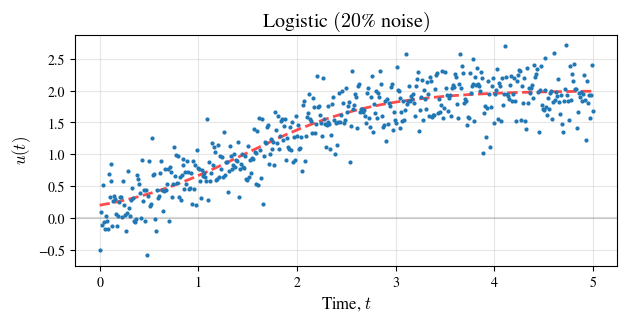

In [5]:
# IMPORT THE DATA
data_path = '../Datasets/logistic.txt'
torch.manual_seed(0);

# Read in CSV data
U0 = torch.tensor(np.loadtxt(data_path, delimiter=','))
U = U0 if noise == 0 else add_noise(U0, noise)
print(f"Imported tensor with shape: {U.numpy().shape}")

# Time
[T, Nt] = [5, 501]
t = torch.linspace(0, T, Nt)

# Preview the data
plt.figure(figsize=(7,3))
plt.axhline(0, color='gray', alpha=0.3)
plt.plot(t, U0, '--', color='r', lw=2, alpha=0.7)
plt.plot(t, U, '.', ms=4)
plt.xlabel('Time, $t$')
plt.ylabel('$u(t)$')
plt.title(f'Logistic $({noise*100:.0f}$% noise$)$')
plt.grid(True, alpha=0.3)
plt.show()

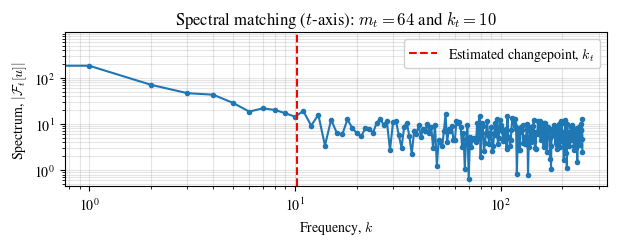

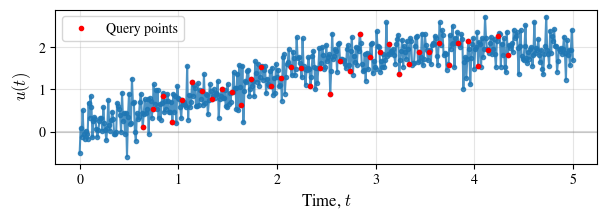

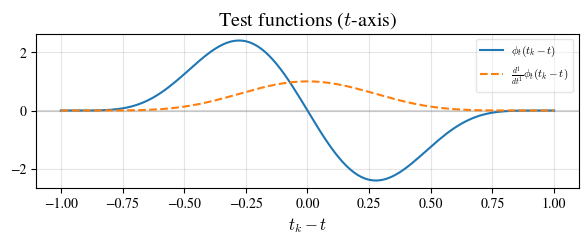

In [6]:
# Temporal grid
grid = [t]

# Derivative operators to include in library
derivatives = [[1], # d/dt
               [0]] # identity

# Candidate monomial terms to include in library
monomials = [[0], # constant
             [1], # u^1
             [2]] # u^2

model = WSINDy(U, derivatives, monomials, grid, equation_type='ode')

In [9]:
# Create standard library terms
[G,powers,derivs,rhs_names] = model.create_default_library()

# Display the library rendered in LaTex
lib_string = fr'\Theta({model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

# Define the WSINDy linear system
model.build_lhs()
model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
w = model.MSTLS()
model.print_report()

# Print out the symbolic equation
pde = symbolic_eqn(model.lhs_name, model.rhs_names, model.coeffs)
display(Math(pde))

100%|██████████| 1/1 [00:00<00:00, 777.15it/s]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [64]
test_fcn_poly_degrees = [7]
subsample_rate = [10]
t_scale = 1.56
u_scale = 0.73
aux_scales = []

LIBRARY
Number of query points = 38
Number of candidate terms = 3
cond(G) = 5.33e+01

RESULTS
ODE: u_{t} = + 1.50(u) - 0.73(u^2)
R^2 = 0.69
Nonzero terms = 2
Lambda = 8.69e-02
Loss = 0.71
Relative L2 error = 0.33


<IPython.core.display.Math object>

### **LOTKA-VOLTERRA**

Now, here's an example with a 2-dimensional nonlinear ODE:
$$
\begin{align*}
  \begin{cases}
    \dot{x} = +ax - xy,\\
    \dot{y} = -by + xy,
  \end{cases}
  \quad \text{with} \quad
  \begin{cases}
    a = 1.5,
    \\
    b = 3.
  \end{cases}
\end{align*}
$$

In [10]:
# Add observation noise?
noise = 0.1

Imported tensors with shape: (1001,)


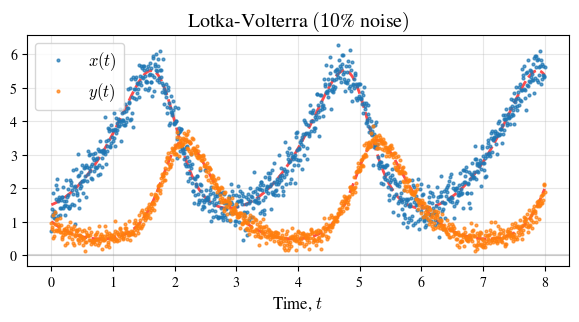

In [30]:
# IMPORT THE DATA
data_path = '../Datasets/lotka_volterra.txt'
torch.manual_seed(0);

# Read in CSV data
[X0, Y0] = torch.tensor(np.loadtxt(data_path, delimiter=','))
X = X0 if noise == 0 else add_noise(X0, noise)
Y = Y0 if noise == 0 else add_noise(Y0, noise)
print(f"Imported tensors with shape: {X.numpy().shape}")

# Time
[T, Nt] = [8, 1001]
t = torch.linspace(0, T, Nt)

# Preview the data
plt.figure(figsize=(7,3))
plt.axhline(0, color='gray', alpha=0.3)
plt.plot(t, X0, '--', color='r', lw=2, alpha=0.7)
plt.plot(t, Y0, '--', color='r', lw=2, alpha=0.7)
plt.plot(t, X, '.', ms=4, label='$x(t)$', alpha=0.7)
plt.plot(t, Y, '.', ms=4, label='$y(t)$', alpha=0.7)
plt.xlabel('Time, $t$')
plt.title(f'Lotka-Volterra $({noise*100:.0f}$% noise$)$')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.show()

In [26]:
# Temporal grid
grid = [t]

# Derivative operators to include in library
derivatives = [[1], # d/dt
               [0]] # identity

# Candidate monomial terms to include in library
monomials = [[0,0], # constant
             [1,0], # x^1
             [2,0], # x^2
             [1,1], # x^1 * y^1
             [0,1], # y^1
             [0,2]] # y^2

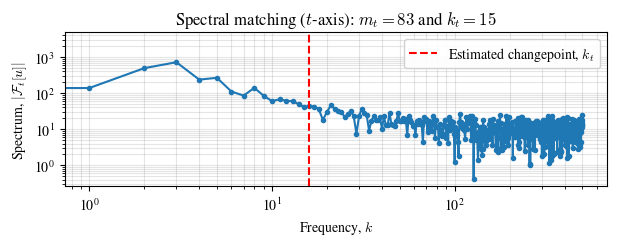

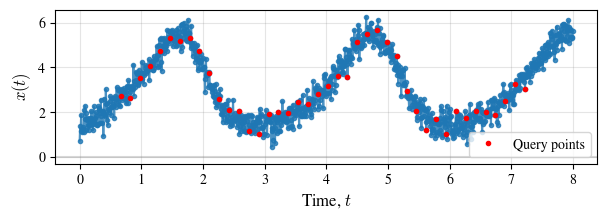

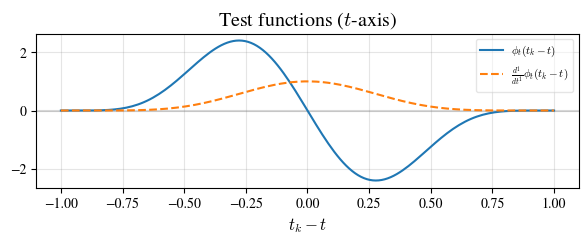

100%|██████████| 1/1 [00:00<00:00, 685.46it/s]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [83]
test_fcn_poly_degrees = [7]
subsample_rate = [20]
t_scale = 1.51
u_scale = 0.47
aux_scales = [0.61]

LIBRARY
Number of query points = 42
Number of candidate terms = 6
cond(G) = 2.69e+02

RESULTS
ODE: x_{t} = + 1.49(x) - 0.99(x y)
R^2 = 1.00
Nonzero terms = 2
Lambda = 8.69e-02
Loss = 0.35
Relative L2 error = 0.05


<IPython.core.display.Math object>

In [31]:
# MODEL FOR THE X VARIABLE
params = {
    'equation_type': 'ode',
    'aux_vars': [Y],
    'var_names': ['x','y']
}
x_model = WSINDy(X, derivatives, monomials, grid, **params)

# Create standard library terms
[G,powers,derivs,rhs_names] = x_model.create_default_library()
lib_string = fr'\Theta({x_model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

# Define the WSINDy linear system
x_model.build_lhs()
x_model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
_ = x_model.MSTLS()
x_model.print_report()

# Print out the symbolic equation
pde = symbolic_eqn(x_model.lhs_name, x_model.rhs_names, x_model.coeffs)
display(Math(pde))

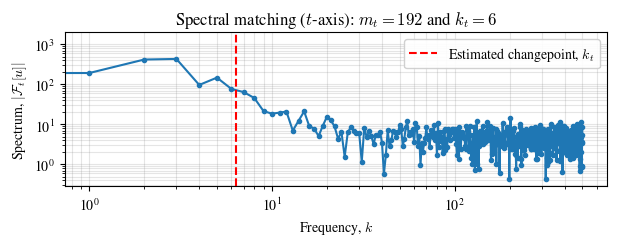

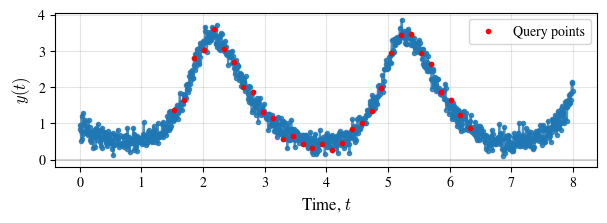

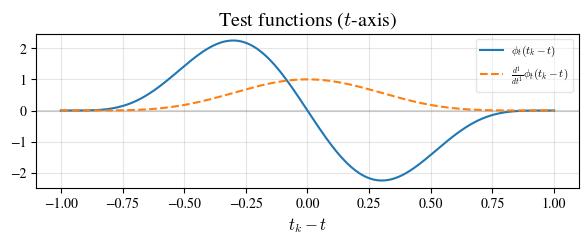

100%|██████████| 1/1 [00:00<00:00, 874.18it/s]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [192]
test_fcn_poly_degrees = [6]
subsample_rate = [20]
t_scale = 0.65
u_scale = 0.61
aux_scales = [0.47]

LIBRARY
Number of query points = 31
Number of candidate terms = 6
cond(G) = 2.60e+03

RESULTS
ODE: y_{t} = - 3.03(y) + 1.00(y x)
R^2 = 1.00
Nonzero terms = 2
Lambda = 1.53e-01
Loss = 0.35
Relative L2 error = 0.04


<IPython.core.display.Math object>

In [32]:
# MODEL FOR THE Y VARIABLE
params = {
    'equation_type': 'ode',
    'aux_vars': [X],
    'var_names': ['y','x']
}
y_model = WSINDy(Y, derivatives, monomials, grid, **params)

# Create standard library terms
[G,powers,derivs,rhs_names] = y_model.create_default_library()
lib_string = fr'\Theta({y_model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

# Define the WSINDy linear system
y_model.build_lhs()
y_model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
_ = y_model.MSTLS()
y_model.print_report()

# Print out the symbolic equation
pde = symbolic_eqn(y_model.lhs_name, y_model.rhs_names, y_model.coeffs)
display(Math(pde))

### **LORENZ '63**

The all-time classic:
\begin{align*}
  \begin{cases}
    \dot{x} = \sigma(y-x),\\
    \dot{y} = x(\rho-z)-y,\\
    \dot{z} = xy-\beta z,
  \end{cases}
  \quad \text{with} \quad
  \begin{cases}
    \sigma = 10,
    \\
    \rho = 28,
    \\
    \beta = 8/3.
  \end{cases}
\end{align*}

For each state equation below, the library is ordered with the left-hand-side state first and the remaining states as auxiliaries.

*Note:* at $5\%$ noise with $\lambda = 10^{-1}$, MSTLS thresholds out the small $-y$ term in $\dot y$ (its magnitude is $28\times$ smaller than the $\rho x$ term). Using $1\%$ noise and $\lambda = 10^{-2}$ recovers the full system.

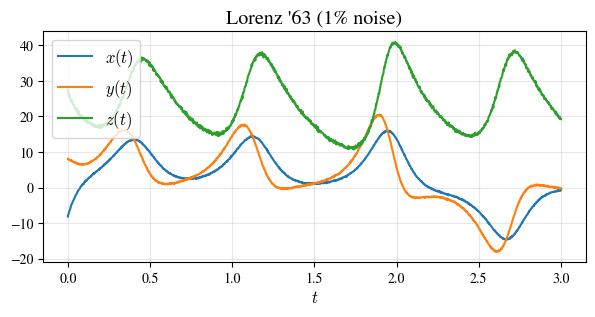

In [ ]:
sigma = 10.0
rho = 28.0
beta_param = 8/3
t = np.linspace(0, 3, 1501)

def lorenz_rhs(t, z):
  x,y,z0 = z
  return [sigma*(y - x),
          x*(rho - z0) - y,
          x*y - beta_param*z0]

sol = solve_ivp(lorenz_rhs, (t[0], t[-1]), [-8.0, 8.0, 27.0], t_eval=t, rtol=1e-12, atol=1e-12, method='DOP853')

noise = 0.01
t = torch.tensor(t, dtype=torch.float64)
lorenz_clean = to_torch_solution(sol)
torch.manual_seed(0)
[x,y,z] = add_noise_to_states(lorenz_clean, noise)

plot_states(t, [x,y,z], ['x','y','z'], f"Lorenz '63 ({noise*100:.0f}% noise)")

In [17]:
beta = [[0,0,0],
        [1,0,0],
        [0,1,0],
        [0,0,1],
        [2,0,0],
        [1,1,0],
        [1,0,1],
        [0,2,0],
        [0,1,1],
        [0,0,2]]

[models, odes] = fit_wsindy_system([x,y,z], t, ['x','y','z'], beta, m=[24], p=[12], s=[8], Lambda=1e-2)
check_recovery(models[0], {'(x)': -10.0, '(y)': 10.0}, tol=0.05)
check_recovery(models[1], {'(x)': 28.0, '(y)': -1.0, '(x z)': -1.0}, tol=0.05)
check_recovery(models[2], {'(z)': -8/3, '(x y)': 1.0}, tol=0.05)


  0%|          | 0/1 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00, 731.86it/s]

<IPython.core.display.Math object>

HYPER-PARAMETERS
m = [24]
p = [12]
s = [8]
yt = 20.833
yu = 0.289
Aux. scales = [0.259, 0.182]

LIBRARY
Num. query points = 182
Num. terms = 10
cond(G) = 6.963e+02

RESULTS
ODE: x_{t} = - 10.00(x) + 10.00(y)
Nonzero terms = 2
Rel. L2 error = 0.034
R^2 = 0.999
Lambda = 1.000e-02
Loss = 0.202



  0%|          | 0/1 [00:00<?, ?it/s]

...

HYPER-PARAMETERS
m = [24]
p = [12]
s = [8]
yt = 20.833
yu = 0.182
Aux. scales = [0.289, 0.259]

LIBRARY
Num. query points = 182
Num. terms = 10
cond(G) = 6.963e+02

RESULTS
ODE: z_{t} = - 2.66(z) + 1.00(x y)
Nonzero terms = 2
Rel. L2 error = 0.055
R^2 = 0.997
Lambda = 1.000e-02
Loss = 0.204


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Verified: (x) = -9.9986 (true -10), (y) = 9.9966 (true 10)
Verified: (x) = 28.0172 (true 28), (y) = -0.9949 (true -1), (x z) = -1.0006 (true -1)
Verified: (z) = -2.6635 (true -2.66667), (x y) = 0.9995 (true 1)


## **HYPERPARAMETER SWEEPS**

The `hyperparameter_sweep` method probes model recovery over a grid of MSTLS thresholds $\lambda$, test function support radii $m$, and `rescale` on/off (using `s=1`, i.e. the maximum number of query points). Each row of the returned dictionary records the identified model, its nonzero terms and coefficients, and validation metrics (sparsity, MSTLS loss, $R^2$, relative $L^2$ residual, $\kappa(G)$); `csv_path` optionally saves the table, and passing a ground-truth `truth` dictionary adds a maximum relative coefficient error column ($E_\infty$, with dropped terms counted as zero coefficients). By default, `m_values` scales the base model's $m$ by factors $\{0.5, 0.75, 1, 1.25, 1.5\}$ and `Lambdas` uses the same 50-point grid scanned by `MSTLS`.

The heatmaps show sparsity, $R^2$, and $\log_{10}$ coefficient error over the $m$–$\lambda$ plane: a wide plateau at the true model size with $R^2 \approx 1$ marks the stable recovery region.


  0%|          | 0/5 [00:00<?, ?it/s]


  0%|          | 0/1 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00, 993.20it/s]


  0%|          | 0/1 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00, 996.27it/s]

...


  0%|          | 0/1 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00, 1116.99it/s]


  0%|          | 0/1 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00, 954.12it/s]


100%|██████████| 5/5 [00:00<00:00, 22.09it/s]

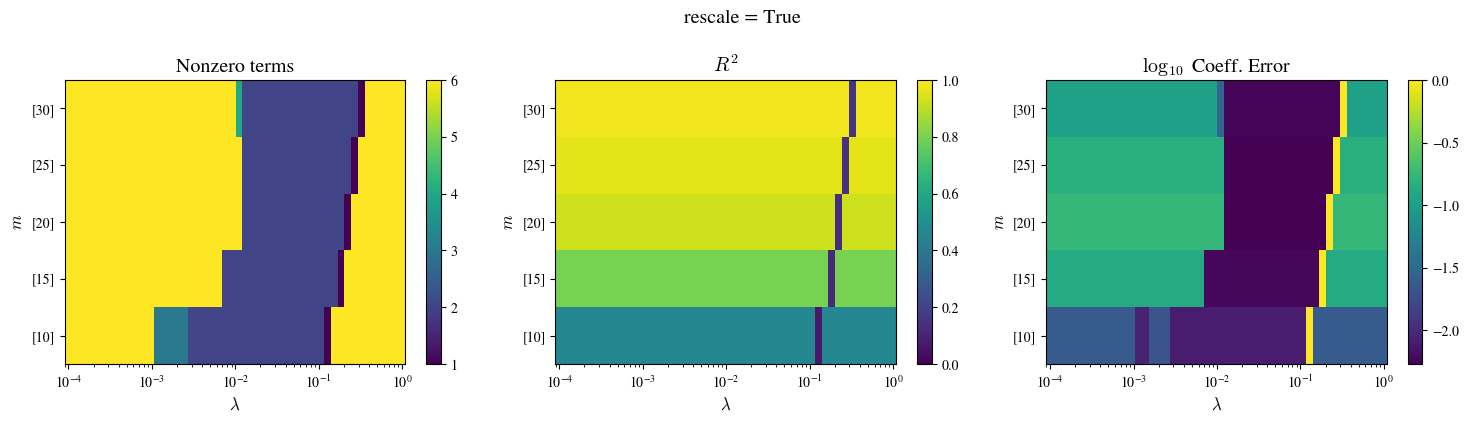

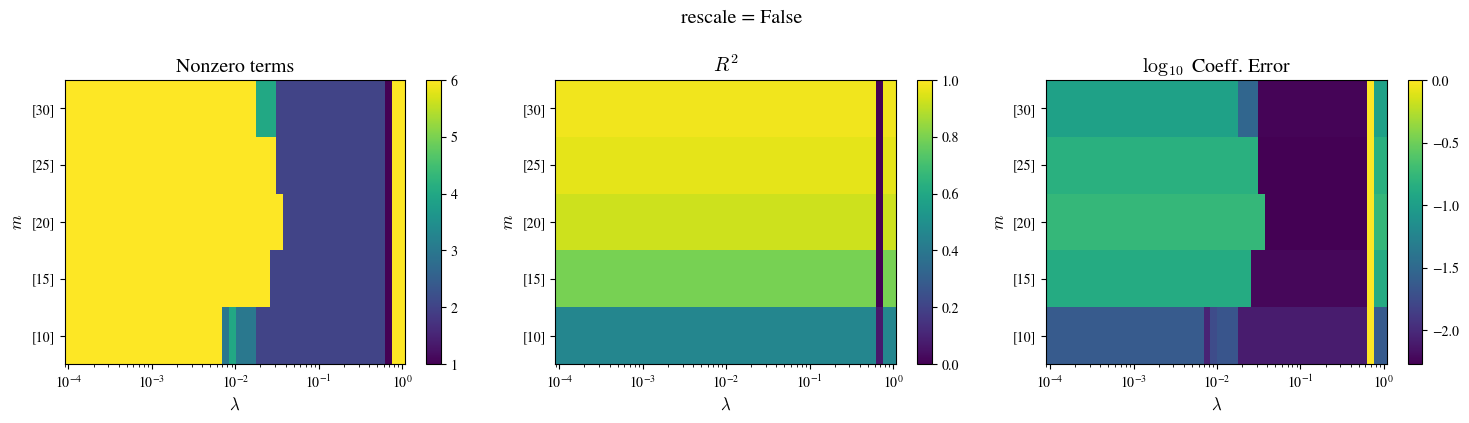

In [ ]:
# Lotka-Volterra x-equation at 5% noise, default m and Lambda grids
t = torch.tensor(np.linspace(0, 8, 1001))
torch.manual_seed(0)
[x,y] = add_noise_to_states(lv_clean, 0.05)

beta = [[0,0],
        [1,0],
        [0,1],
        [2,0],
        [1,1],
        [0,2]]

model = WSINDy(x, [[1],[0]], beta, t, aux_vars=[y], names=['x','y'], m=[20], p=[10], s=[5],
               verbosity=False, equation_type='ode')
truth = {'(x)': 1.5, '(x y)': -1.0}
results = model.hyperparameter_sweep(lhs_name='x_{t}', truth=truth)

In [21]:
# Most common models across the sweep
from collections import Counter

for model_str,count in Counter(results['model']).most_common(4):
  print(f'{count:3d}/{len(results["model"])} fits: {model_str}')

 96/500 fits: x_{t} = + 1.50(x) - 0.99(x y)
 72/500 fits: x_{t} = + 1.49(x) - 0.99(x y)
 68/500 fits: x_{t} = + 0.56(1) + 1.24(x) - 0.33(y) + 0.04(x^2) - 0.98(x y) + 0.07(y^2)
 66/500 fits: x_{t} = + 0.49(1) + 1.27(x) - 0.30(y) + 0.03(x^2) - 0.97(x y) + 0.06(y^2)



  0%|          | 0/5 [00:00<?, ?it/s]


  0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 5/5 [00:00<00:00, 266.81it/s]


  0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 5/5 [00:00<00:00, 395.91it/s]

...


100%|██████████| 5/5 [00:00<00:00, 331.71it/s]


  0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 5/5 [00:00<00:00, 334.24it/s]


100%|██████████| 5/5 [00:01<00:00,  4.88it/s]


100%|██████████| 5/5 [00:01<00:00,  4.57it/s]

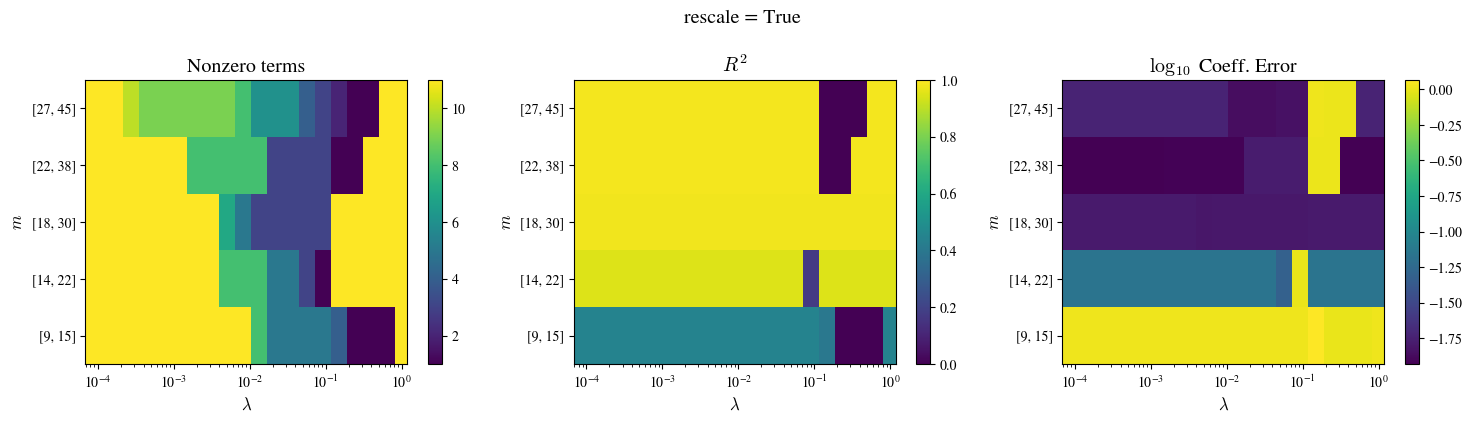

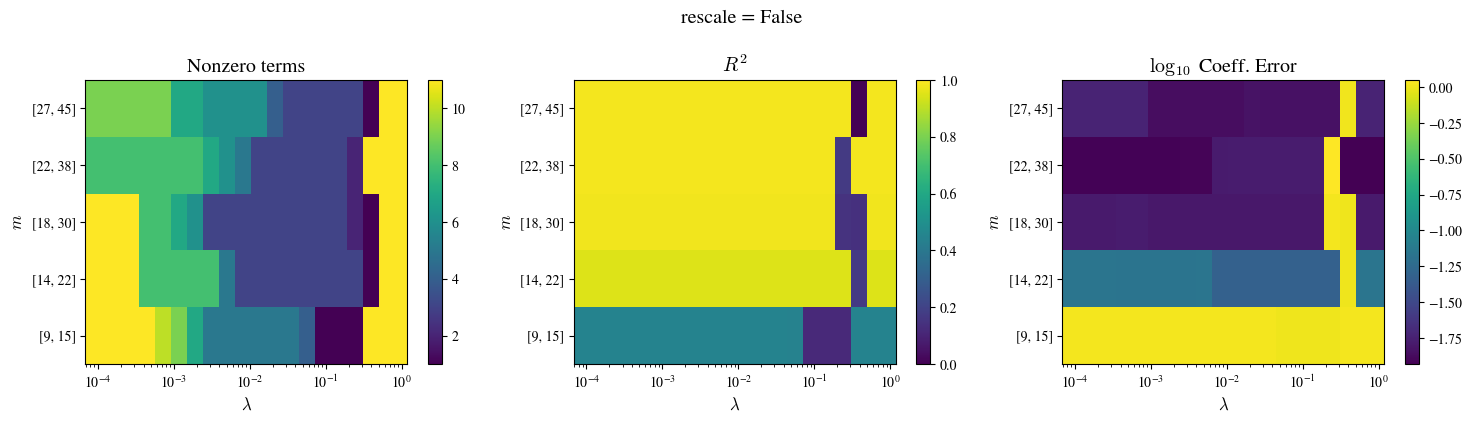

 24/200 fits: u_{t} = - 0.49(u^2)_{x} - 0.99(u)_{xx} - 1.00(u)_{xxxx}
 18/200 fits: u_{t} = + 0.00(1) + 0.12(u) - 0.00(u^2) + 0.01(u)_{x} - 0.27(u^2)_{x} + 0.04(u)_{xx} - 0.00(u^2)_{xx} + 0.01(u)_{xxx} - 0.06(u^2)_{xxx} - 0.09(u)_{xxxx} - 0.00(u^2)_{xxxx}
 18/200 fits: u_{t} = + 0.00(1) + 0.01(u) - 0.00(u^2) + 0.01(u)_{x} - 0.48(u^2)_{x} - 0.93(u)_{xx} - 0.00(u^2)_{xx} + 0.01(u)_{xxx} - 0.01(u^2)_{xxx} - 0.94(u)_{xxxx} - 0.00(u^2)_{xxxx}
 18/200 fits: u_{t} = + 0.00(1) + 0.00(u) - 0.00(u^2) + 0.00(u)_{x} - 0.49(u^2)_{x} - 0.99(u)_{xx} - 0.00(u^2)_{xx} + 0.01(u)_{xxx} + 0.00(u^2)_{xxx} - 1.00(u)_{xxxx} + 0.00(u^2)_{xxxx}


In [22]:
# Kuramoto Sivashinsky at 20% noise, reduced Lambda grid, results saved to CSV
U = torch.tensor(np.loadtxt('../Datasets/KS.txt', delimiter=','))
torch.manual_seed(0)
U = add_noise(U, 0.2).view(256, -1)
x = torch.linspace(0, 32*np.pi, 256)
t = torch.linspace(0, 150, 301)

alpha = [[0,1],
         [0,0],
         [1,0],
         [2,0],
         [3,0],
         [4,0]]

beta = [[0],
        [1],
        [2]]

model = WSINDy(U, alpha, beta, [x,t], m=[18,30], verbosity=False, equation_type='pde')
truth = {'(u^2)_{x}': -0.5, '(u)_{xx}': -1.0, '(u)_{xxxx}': -1.0}
Lambdas = 10**((4/19)*torch.arange(0,20)-4)
results = model.hyperparameter_sweep(lhs_name='u_{t}', Lambdas=Lambdas, truth=truth, csv_path='ks_sweep.csv')

for model_str,count in Counter(results['model']).most_common(4):
  print(f'{count:3d}/{len(results["model"])} fits: {model_str}')